# Occupation

In [1]:
import pandas as pd
import numpy as np

### Step 2. Import the dataset from this [address](https://raw.githubusercontent.com/justmarkham/DAT8/master/data/u.user). 

### Step 3. Assign it to a variable called users.

In [7]:
users = pd.read_csv("https://raw.githubusercontent.com/justmarkham/DAT8/master/data/u.user",
            sep="|")

users

,user_id,age,gender,occupation,zip_code
0,1,24,M,technician,85711
1,2,53,F,other,94043
2,3,23,M,writer,32067
3,4,24,M,technician,43537
4,5,33,F,other,15213
...,...,...,...,...,...
938,939,26,F,student,33319
939,940,32,M,administrator,02215
940,941,20,M,student,97229
941,942,48,F,librarian,78209


In [15]:
users = users.set_index("user_id")
users

,age,gender,occupation,zip_code
user_id,,,,
1,24,M,technician,85711
2,53,F,other,94043
3,23,M,writer,32067
4,24,M,technician,43537
5,33,F,other,15213
...,...,...,...,...
939,26,F,student,33319
940,32,M,administrator,02215
941,20,M,student,97229


In [16]:
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 943 entries, 1 to 943
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   age         943 non-null    int64
 1   gender      943 non-null    str  
 2   occupation  943 non-null    str  
 3   zip_code    943 non-null    str  
dtypes: int64(1), str(3)
memory usage: 42.6 KB


### Step 4. Discover what is the mean age per occupation

In [20]:
users.occupation.nunique()

21

<Axes: ylabel='occupation'>

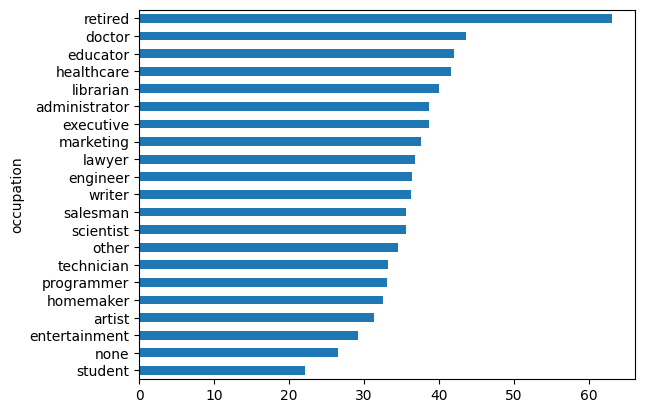

In [34]:
users.groupby("occupation")["age"].mean().sort_values(ascending=True).plot.barh()

In [45]:
users["mean_age_per_occupation"] = users.groupby("occupation")["age"].transform("mean").round().astype("int")

In [46]:
users

,age,gender,occupation,zip_code,mean_age_per_occupation
user_id,,,,,
1,24,M,technician,85711,33
2,53,F,other,94043,35
3,23,M,writer,32067,36
4,24,M,technician,43537,33
5,33,F,other,15213,35
...,...,...,...,...,...
939,26,F,student,33319,22
940,32,M,administrator,02215,39
941,20,M,student,97229,22


In [47]:
users["mean_age_per_occupation"] - users["age"]

user_id
1       9
2     -18
3      13
4       9
5       2
       ..
939    -4
940     7
941     2
942    -8
943     0
Length: 943, dtype: int64

In [ ]:
users.uns

,age,gender,occupation,zip_code,mean_age_per_occupation
user_id,,,,,
1,24,M,technician,85711,33
2,53,F,other,94043,35
3,23,M,writer,32067,36
4,24,M,technician,43537,33
5,33,F,other,15213,35
...,...,...,...,...,...
939,26,F,student,33319,22
940,32,M,administrator,02215,39
941,20,M,student,97229,22


In [67]:
users.groupby(["occupation","gender"])[["age"]].mean().unstack()

age           
gender                 F          M
occupation                         
administrator  40.638889  37.162791
artist         30.307692  32.333333
doctor               NaN  43.571429
educator       39.115385  43.101449
engineer       29.500000  36.600000
entertainment  31.000000  29.000000
executive      44.000000  38.172414
healthcare     39.818182  45.400000
homemaker      34.166667  23.000000
lawyer         39.500000  36.200000
librarian      40.000000  40.000000
marketing      37.200000  37.875000
none           36.500000  18.600000
other          35.472222  34.028986
programmer     32.166667  33.216667
retired        70.000000  62.538462
salesman       27.000000  38.555556
scientist      28.333333  36.321429
student        20.750000  22.669118
technician     38.000000  32.961538
writer         37.631579  35.346154

### Step 5. Discover the Male ratio per occupation and sort it from the most to the least

In [72]:
users.groupby(["occupation","gender"]).count()

age  zip_code  mean_age_per_occupation
occupation    gender                                        
administrator F        36        36                       36
              M        43        43                       43
artist        F        13        13                       13
              M        15        15                       15
doctor        M         7         7                        7
educator      F        26        26                       26
              M        69        69                       69
engineer      F         2         2                        2
              M        65        65                       65
entertainment F         2         2                        2
              M        16        16                       16
executive     F         3         3                        3
              M        29        29                       29
healthcare    F        11        11                       11
              M         5         5                        5
homemaker     F         6         6                        6
              M         1         1                        1
lawyer        F         2         2                        2
              M        10        10                       10
librarian     F        29        29                       29
              M        22        22                       22
marketing     F        10        10                       10
              M        16        16                       16
none          F         4         4                        4
              M         5         5                        5
other         F        36        36                       36
              M        69        69                       69
programmer    F         6         6                        6
              M        60        60                       60
retired       F         1         1                        1
              M        13        13                       13
salesman      F         3         3                        3
              M         9         9                        9
scientist     F         3         3                        3
              M        28        28                       28
student       F        60        60                       60
              M       136       136                      136
technician    F         1         1                        1
              M        26        26                       26
writer        F        19        19                       19
              M        26        26                       26

,age,occupation,zip_code
gender,,,
F,273,273,273
M,670,670,670


,age,gender,occupation,zip_code,gender_n
user_id,,,,,
1,24,M,technician,85711,1
2,53,F,other,94043,0
3,23,M,writer,32067,1
4,24,M,technician,43537,1
5,33,F,other,15213,0
...,...,...,...,...,...
939,26,F,student,33319,0
940,32,M,administrator,02215,1
941,20,M,student,97229,1


tipo de x: <class 'pandas.core.frame.DataFrame'>
         age gender     occupation zip_code  gender_n     ratio
user_id                                                        
7         57      M  administrator    91344         1  0.577778
8         36      M  administrator    05201         1  0.577778
34        38      F  administrator    42141         0  0.577778
42        30      M  administrator    17870         1  0.577778
48        45      M  administrator    12550         1  0.577778
...      ...    ...            ...      ...       ...       ...
873       48      F  administrator    33763         0  0.577778
879       33      F  administrator    55337         0  0.577778
891       51      F  administrator    03062         0  0.577778
922       29      F  administrator    21114         0  0.577778
940       32      M  administrator    02215         1  0.577778

[79 rows x 6 columns]
tipo de x: <class 'pandas.core.frame.DataFrame'>
         age gender occupation zip_code  gender

,age,gender,occupation,zip_code,gender_n,ratio
user_id,,,,,,
1,24,M,technician,85711,1,0.962963
2,53,F,other,94043,0,0.657143
3,23,M,writer,32067,1,0.577778
4,24,M,technician,43537,1,0.962963
5,33,F,other,15213,0,0.657143
...,...,...,...,...,...,...
939,26,F,student,33319,0,0.693878
940,32,M,administrator,02215,1,0.544304
941,20,M,student,97229,1,0.693878


,age,gender,occupation,zip_code,gender_n,ratio
user_id,,,,,,
1,24,M,technician,85711,1,0.577778
2,53,F,other,94043,0,0.577778
3,23,M,writer,32067,1,0.577778
4,24,M,technician,43537,1,0.577778
5,33,F,other,15213,0,0.577778
...,...,...,...,...,...,...
939,26,F,student,33319,0,0.577778
940,32,M,administrator,02215,1,0.577778
941,20,M,student,97229,1,0.577778


,occupation,gender,ratio
0,administrator,F,45.569620
1,administrator,M,54.430380
2,artist,F,46.428571
3,artist,M,53.571429
4,doctor,M,100.000000
5,educator,F,27.368421
6,educator,M,72.631579
7,engineer,F,2.985075
8,engineer,M,97.014925
9,entertainment,F,11.111111


occupation
administrator     43
artist            15
doctor             7
educator          69
engineer          65
entertainment     16
executive         29
healthcare         5
homemaker          1
lawyer            10
librarian         22
marketing         16
none               5
other             69
programmer        60
retired           13
salesman           9
scientist         28
student          136
technician        26
writer            26
Name: gender_n, dtype: int64

student          196
other            105
educator          95
administrator     79
engineer          67
programmer        66
librarian         51
writer            45
executive         32
scientist         31
artist            28
technician        27
marketing         26
entertainment     18
healthcare        16
retired           14
lawyer            12
salesman          12
none               9
homemaker          7
doctor             7
Name: occupation, dtype: int64

doctor           100.0%
engineer         97.01%
technician        96.3%
retired          92.86%
programmer       90.91%
executive        90.62%
scientist        90.32%
entertainment    88.89%
lawyer           83.33%
salesman          75.0%
educator         72.63%
student          69.39%
other            65.71%
marketing        61.54%
writer           57.78%
none             55.56%
administrator    54.43%
artist           53.57%
librarian        43.14%
healthcare       31.25%
homemaker        14.29%
dtype: object

### Step 6. For each occupation, calculate the minimum and maximum ages

,min,max
occupation,,
administrator,21,70
artist,19,48
doctor,28,64
educator,23,63
engineer,22,70
entertainment,15,50
executive,22,69
healthcare,22,62
homemaker,20,50


### Step 7. For each combination of occupation and gender, calculate the mean age

age
occupation    gender           
administrator F       40.638889
              M       37.162791
artist        F       30.307692
              M       32.333333
doctor        M       43.571429
educator      F       39.115385
              M       43.101449
engineer      F       29.500000
              M       36.600000
entertainment F       31.000000
              M       29.000000
executive     F       44.000000
              M       38.172414
healthcare    F       39.818182
              M       45.400000
homemaker     F       34.166667
              M       23.000000
lawyer        F       39.500000
              M       36.200000
librarian     F       40.000000
              M       40.000000
marketing     F       37.200000
              M       37.875000
none          F       36.500000
              M       18.600000
other         F       35.472222
              M       34.028986
programmer    F       32.166667
              M       33.216667
retired       F       70.000000
              M       62.538462
salesman      F       27.000000
              M       38.555556
scientist     F       28.333333
              M       36.321429
student       F       20.750000
              M       22.669118
technician    F       38.000000
              M       32.961538
writer        F       37.631579
              M       35.346154

### Step 8.  For each occupation present the percentage of women and men

occupation     gender
administrator  M          54.430380
               F          45.569620
artist         M          53.571429
               F          46.428571
doctor         M         100.000000
educator       M          72.631579
               F          27.368421
engineer       M          97.014925
               F           2.985075
entertainment  M          88.888889
               F          11.111111
executive      M          90.625000
               F           9.375000
healthcare     F          68.750000
               M          31.250000
homemaker      F          85.714286
               M          14.285714
lawyer         M          83.333333
               F          16.666667
librarian      F          56.862745
               M          43.137255
marketing      M          61.538462
               F          38.461538
none           M          55.555556
               F          44.444444
other          M          65.714286
               F          34.285714
progra